# Set Up

In [13]:
import pandas as pd
pd.set_option('display.max_columns', None)
import numpy as np
import math
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_curve, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, f1_score, classification_report, roc_curve
import joblib
import tensorflow as tf
from tensorflow.keras import layers, models

In [14]:
# Environment variables
WINDOW = 5 # context window
KIN_FEATURES = ["spd1", "spd2"]  
KEEP_COLUMNS = ['sender', 'exchangedMessageType',
'hazardOccurrence', 'hazardAttack', 'maxSpeed', 'maxDeceleration', 'pos1', 'pos2', 'spd1', 'spd2', 
'sender_GPS1', 'sender_GPS2']
DROP_COLS = ['vehicleId', 'sender', 'rcvTime']

# Sub-sampling
RATIO = 12252
ALL_ATTACKS = 3063
ATTACK_PER_BENIGN = 4

# Sliding Window creation
TARGET_COL = "hazardAttack"
INPUT_LEN = 90
OFFSET = 1

# Model creation
NODES_FIRST = 64
NODES_SECOND = 32

# Hyperparameters
EPOCHS = 300
BATCH_SIZE = 128
VALIDATION_SPLIT = 0.1
PATIENCE = 5
LEARNING_RATE = 1e-4

# K-Fold
N_SPLITS  = 5

THRESHOLD = 0.6 # To be changed for each model after k-fold validation

# Load and Clean Data

In [15]:
df = pd.read_csv("all_JSON_split.csv", index_col=False) # sorted_attacks_with_context.csv

# Sort by time (adjust column name if needed)
df = df.sort_values("rcvTime").reset_index(drop=True)
df = df[df['type']==3]
df.drop(columns="Unnamed: 0", inplace=True)
df.head()

,type,rcvTime,vehicleId,sendTime,sender,senderPseudo,messageID,exchangedMessageType,EventID,EventType,RoadID,hazardOccurrencePercentage,hazardOccurrence,hazardAttack,laneIndex,lanePosition,maxSpeed,maxDeceleration,pos1,pos2,pos_noise1,pos_noise2,spd1,spd2,spd_noise1,spd_noise2,acl1,acl2,acl_noise1,acl_noise2,hed1,hed2,hed_noise1,hed_noise2,sender_GPS1,sender_GPS2,currentDirection1,currentDirection2
37,3,9.264662,9,9.264662,39.0,10399.0,25413.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,18.0,50.0,4.0,11382.933875,1595.138112,3.584624,3.697030,-12.301525,9.769453,0.017753,-0.014097,-1.742700,1.384111,0.019196,0.012654,-0.776963,0.629546,29.361583,3.230346,6.185602,49.638862,-0.783122,0.621868
38,3,9.602877,39,9.602877,9.0,1091.0,25491.0,0.0,0.0,NaN,NaN,55.0,0.0,0.0,1.0,44.0,70.0,4.0,11247.012310,1726.826189,4.920851,5.141217,-20.194382,24.143206,0.030838,-0.036858,-1.149188,1.376274,0.002167,0.002590,-0.623807,0.781578,13.115805,0.155682,6.183790,49.637633,-0.641695,0.766960
45,3,10.264663,9,10.264663,39.0,10399.0,25569.0,0.0,0.0,NaN,NaN,68.0,0.0,0.0,0.0,34.0,50.0,4.0,11369.767936,1605.583379,3.565704,3.531391,-13.767003,10.932933,0.019867,-0.015776,-1.284354,1.020328,0.002115,0.001679,-0.776963,0.629546,33.995276,2.875504,6.185425,49.638764,-0.783122,0.621868
46,3,10.602879,39,10.602879,9.0,1091.0,25607.0,0.0,0.0,NaN,NaN,55.0,0.0,0.0,1.0,76.0,70.0,4.0,11226.946438,1752.394112,4.828441,4.813102,-20.434389,26.607918,0.031204,-0.040622,-1.567768,2.043837,0.000366,0.003764,-0.586226,0.810147,13.433746,0.121668,6.183526,49.637397,-0.609173,0.793038
53,3,11.264664,9,11.264664,39.0,10399.0,25645.0,0.0,0.0,NaN,NaN,68.0,0.0,0.0,0.0,53.0,50.0,4.0,11355.354090,1617.230823,3.622207,3.589321,-15.134886,12.354389,0.021842,-0.017827,-1.676053,1.368541,0.001975,0.002050,-0.759240,0.650810,38.980713,2.494628,6.185232,49.638654,-0.774721,0.632303


In [16]:
df = df.fillna(0)
df.isnull().any()

type                          False
rcvTime                       False
vehicleId                     False
sendTime                      False
sender                        False
senderPseudo                  False
messageID                     False
exchangedMessageType          False
EventID                       False
EventType                     False
RoadID                        False
hazardOccurrencePercentage    False
hazardOccurrence              False
hazardAttack                  False
laneIndex                     False
lanePosition                  False
maxSpeed                      False
maxDeceleration               False
pos1                          False
pos2                          False
pos_noise1                    False
pos_noise2                    False
spd1                          False
spd2                          False
spd_noise1                    False
spd_noise2                    False
acl1                          False
acl2                        

In [17]:
df = df.drop(columns='RoadID')
# Get one hot encoding of columns B
one_hot = pd.get_dummies(df['EventType'])
# Drop column B as it is now encoded
df = df.drop('EventType',axis = 1)
# Join the encoded df
df = df.join(one_hot) # Creates a binary column called "Accident"

In [18]:
df = df.rename(columns={0:"no_accident"})
df.head()

,type,rcvTime,vehicleId,sendTime,sender,senderPseudo,messageID,exchangedMessageType,EventID,hazardOccurrencePercentage,hazardOccurrence,hazardAttack,laneIndex,lanePosition,maxSpeed,maxDeceleration,pos1,pos2,pos_noise1,pos_noise2,spd1,spd2,spd_noise1,spd_noise2,acl1,acl2,acl_noise1,acl_noise2,hed1,hed2,hed_noise1,hed_noise2,sender_GPS1,sender_GPS2,currentDirection1,currentDirection2,no_accident,Accident
37,3,9.264662,9,9.264662,39.0,10399.0,25413.0,0.0,0.0,0.0,0.0,0.0,0.0,18.0,50.0,4.0,11382.933875,1595.138112,3.584624,3.697030,-12.301525,9.769453,0.017753,-0.014097,-1.742700,1.384111,0.019196,0.012654,-0.776963,0.629546,29.361583,3.230346,6.185602,49.638862,-0.783122,0.621868,True,False
38,3,9.602877,39,9.602877,9.0,1091.0,25491.0,0.0,0.0,55.0,0.0,0.0,1.0,44.0,70.0,4.0,11247.012310,1726.826189,4.920851,5.141217,-20.194382,24.143206,0.030838,-0.036858,-1.149188,1.376274,0.002167,0.002590,-0.623807,0.781578,13.115805,0.155682,6.183790,49.637633,-0.641695,0.766960,True,False
45,3,10.264663,9,10.264663,39.0,10399.0,25569.0,0.0,0.0,68.0,0.0,0.0,0.0,34.0,50.0,4.0,11369.767936,1605.583379,3.565704,3.531391,-13.767003,10.932933,0.019867,-0.015776,-1.284354,1.020328,0.002115,0.001679,-0.776963,0.629546,33.995276,2.875504,6.185425,49.638764,-0.783122,0.621868,True,False
46,3,10.602879,39,10.602879,9.0,1091.0,25607.0,0.0,0.0,55.0,0.0,0.0,1.0,76.0,70.0,4.0,11226.946438,1752.394112,4.828441,4.813102,-20.434389,26.607918,0.031204,-0.040622,-1.567768,2.043837,0.000366,0.003764,-0.586226,0.810147,13.433746,0.121668,6.183526,49.637397,-0.609173,0.793038,True,False
53,3,11.264664,9,11.264664,39.0,10399.0,25645.0,0.0,0.0,68.0,0.0,0.0,0.0,53.0,50.0,4.0,11355.354090,1617.230823,3.622207,3.589321,-15.134886,12.354389,0.021842,-0.017827,-1.676053,1.368541,0.001975,0.002050,-0.759240,0.650810,38.980713,2.494628,6.185232,49.638654,-0.774721,0.632303,True,False


# Feature Engineering

In [19]:
df = df.sort_values(["vehicleId", "rcvTime"]).reset_index(drop=True)

for c in KIN_FEATURES:
    df[f"{c}_delta"]     = df.groupby("vehicleId")[c].diff().fillna(0)
    df[f"{c}_roll_mean"] = df.groupby("vehicleId")[c].transform(lambda x: x.rolling(WINDOW).mean()).fillna(0)
    df[f"{c}_roll_std"]  = df.groupby("vehicleId")[c].transform(lambda x: x.rolling(WINDOW).std()).fillna(0)

df["delta_t"] = df.groupby("vehicleId")["rcvTime"].diff().fillna(0)

In [20]:
for c in KIN_FEATURES:
    df[f"{c}_dev_from_mean"] = df.groupby('vehicleId')[c].transform(
        lambda x: x - x.rolling(WINDOW).mean()
    ).fillna(0)
    # Ratio of current std to rolling std (volatility spike detection)
    df[f"{c}_std_ratio"] = df.groupby('vehicleId')[c].transform(
        lambda x: x.rolling(5).std() / (x.rolling(WINDOW).std() + 1e-8)
    ).fillna(1)

In [21]:
df.head(2000)

,type,rcvTime,vehicleId,sendTime,sender,senderPseudo,messageID,exchangedMessageType,EventID,hazardOccurrencePercentage,hazardOccurrence,hazardAttack,laneIndex,lanePosition,maxSpeed,maxDeceleration,pos1,pos2,pos_noise1,pos_noise2,spd1,spd2,spd_noise1,spd_noise2,acl1,acl2,acl_noise1,acl_noise2,hed1,hed2,hed_noise1,hed_noise2,sender_GPS1,sender_GPS2,currentDirection1,currentDirection2,no_accident,Accident,spd1_delta,spd1_roll_mean,spd1_roll_std,spd2_delta,spd2_roll_mean,spd2_roll_std,delta_t,spd1_dev_from_mean,spd1_std_ratio,spd2_dev_from_mean,spd2_std_ratio
0,3,9.264662,9,9.264662,39.0,10399.0,25413.0,0.0,0.0,0.0,0.0,0.0,0.0,18.0,50.0,4.0,11382.933875,1595.138112,3.584624,3.697030,-12.301525,9.769453,0.017753,-0.014097,-1.742700,1.384111,0.019196,0.012654,-0.776963,0.629546,29.361583,3.230346,6.185602,49.638862,-0.783122,0.621868,True,False,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,1.0
1,3,10.264663,9,10.264663,39.0,10399.0,25569.0,0.0,0.0,68.0,0.0,0.0,0.0,34.0,50.0,4.0,11369.767936,1605.583379,3.565704,3.531391,-13.767003,10.932933,0.019867,-0.015776,-1.284354,1.020328,0.002115,0.001679,-0.776963,0.629546,33.995276,2.875504,6.185425,49.638764,-0.783122,0.621868,True,False,-1.465478,0.000000,0.000000,1.163480,0.000000,0.000000,1.000001,0.000000,1.0,0.000000,1.0
2,3,11.264664,9,11.264664,39.0,10399.0,25645.0,0.0,0.0,68.0,0.0,0.0,0.0,53.0,50.0,4.0,11355.354090,1617.230823,3.622207,3.589321,-15.134886,12.354389,0.021842,-0.017827,-1.676053,1.368541,0.001975,0.002050,-0.759240,0.650810,38.980713,2.494628,6.185232,49.638654,-0.774721,0.632303,True,False,-1.367883,0.000000,0.000000,1.421456,0.000000,0.000000,1.000001,0.000000,1.0,0.000000,1.0
3,3,12.264666,9,12.264666,39.0,10399.0,29914.0,0.0,0.0,68.0,0.0,0.0,0.0,74.0,50.0,4.0,11339.678670,1630.709348,3.539763,3.626519,-16.485806,14.099809,0.023792,-0.020345,-1.881717,1.609677,0.001950,0.002519,-0.744104,0.668064,44.619455,2.095115,6.185022,49.638528,-0.760005,0.649917,True,False,-1.350920,0.000000,0.000000,1.745420,0.000000,0.000000,1.000002,0.000000,1.0,0.000000,1.0
4,3,13.264668,9,13.264668,39.0,10399.0,34307.0,0.0,0.0,68.0,0.0,0.0,0.0,96.0,50.0,4.0,11322.812464,1646.022508,3.649937,3.612419,-17.369428,16.117259,0.025069,-0.023255,-1.234016,1.145230,0.001277,0.002909,-0.713442,0.700715,48.748135,1.712575,6.184797,49.638385,-0.733134,0.680085,True,False,-0.883622,-15.011730,2.039692,2.017450,12.654769,2.522745,1.000002,-2.357699,1.0,3.462490,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,3,292.789503,51,292.789503,375.0,103752.0,692009.0,0.0,0.0,77.0,0.0,0.0,1.0,188.0,70.0,4.0,3863.413466,3931.936510,4.240904,4.248831,-6.402983,36.190784,0.014845,-0.083883,-0.097853,0.554961,0.000024,0.000134,-0.167403,0.985889,1.841868,0.026028,6.082845,49.615293,-0.174262,0.984699,True,False,-2.105384,-5.556419,1.153558,11.905081,31.403641,6.522799,0.589396,-0.846564,1.0,4.787142,1.0
1996,3,293.200108,51,293.200108,291.0,102911.0,697228.0,1.0,0.0,50.0,0.0,0.0,0.0,718.0,50.0,4.0,3773.087577,4429.682464,4.420848,4.764215,-4.288214,24.232854,0.001622,-0.009163,0.027465,-0.154644,0.000004,0.000020,-0.058865,0.998266,13.320998,0.768922,6.081863,49.610791,-0.174262,0.984699,True,False,2.114769,-5.133813,1.153735,-11.957930,29.014793,6.524741,0.410606,0.845599,1.0,-4.781939,1.0
1997,3,293.789504,51,293.789504,375.0,103752.0,698886.0,0.0,0.0,77.0,0.0,0.0,1.0,224.0,70.0,4.0,3856.996546,3968.121034,4.312011,4.302557,-6.396647,36.158204,0.014831,-0.083806,0.027591,-0.153893,0.000014,0.000077,-0.167403,0.985889,1.840790,0.026114,6.082776,49.614966,-0.174262,0.984699,True,False,-2.108433,-5.555553,1.152644,11.925351,31.400238,6.518833,0.589396,-0.841094,1.0,4.757966,1.0
1998,3,294.200098,51,294.200098,291.0,102911.0,704190.0,1.0,0.0,50.0,0.0,0.0,0.0,743.0,50.0,4.0,3768.699676,4453.942493,4.349088,4.763325,-4.

In [22]:
# Distance column between the receiver vehicle and the attacker vehicle
unsquared_distance = ((df['pos1']-df['sender_GPS1'])**2)+((df['pos2']-df['sender_GPS2'])**2)
sq_dist = []
print(max(unsquared_distance), min(unsquared_distance))
for u in unsquared_distance:
    a = math.sqrt(u)
    sq_dist.append(a)
df['senderDistance'] = sq_dist
df.head(10)
df.to_csv('VeReMiAP_with_changing_columns.csv')

180371562.38236308 0.0


# Model Builder

In [23]:
# ── MODEL BUILDER ─────────────────────────────────────────────────────────────
def build_model(input_len, n_features):
    model = models.Sequential([
        layers.Input(shape=(input_len, n_features)),
        layers.LSTM(NODES_FIRST, return_sequences=True,
                dropout=0.2, recurrent_dropout=0.1), # Without recurrent_dropout, the recurrent connections can still memorise 
                #exact sequences across those 90 steps even if the input connections are regularised
        layers.LSTM(NODES_SECOND, dropout=0.2),
        layers.Dense(1, activation="sigmoid")
        ])

    model.compile(
        optimizer = tf.keras.optimizers.Adam(LEARNING_RATE),
        loss      = "binary_crossentropy",
        metrics   = [
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.Precision(name="precision")
        ]
    )
    return model

# Sliding Window

In [24]:
def build_sequences_for_vehicle(vehicle_df, input_len, pred_offset):
    ratio_count = 0
    allow_count = 0
    feature_cols = [c for c in vehicle_df.columns if c != TARGET_COL]
    allowing = True
    X, y = [], []

    values = vehicle_df[feature_cols].values.astype("float32")
    labels = vehicle_df[TARGET_COL].values.astype("float32")

    for i in range(len(vehicle_df) - input_len - pred_offset + 1):
        # Skip any window that starts mid-attack
        if labels[i] == 1:
            continue
        y_to_add = labels[i + input_len + pred_offset - 1]
        if (y_to_add == 1) & (allowing == True):
            X.append(values[i:i+input_len])
            y.append(y_to_add)
            allowing = False
        elif (y_to_add == 0) & (ratio_count < RATIO) & (allowing == False):
            X.append(values[i:i+input_len])
            y.append(y_to_add)
            allow_count += 1
            ratio_count += 1
            if allow_count == ATTACK_PER_BENIGN:
                allow_count = 0
                allowing = True
        if (ratio_count == RATIO) & (sum(y) == ALL_ATTACKS):
            break
    return np.array(X), np.array(y)

# K-Fold Validation

In [25]:
# ── STRATIFIED VEHICLE SETUP ──────────────────────────────────────────────────
attack_summary = df.groupby('vehicleId')['hazardAttack'].agg(['sum', 'count'])
attack_summary.columns       = ['attacks', 'total_rows']
attack_summary['attack_rate'] = attack_summary['attacks'] / attack_summary['total_rows']

# Binary tier: 0 = no attacks, 1 = has attacks
attack_summary['tier'] = (attack_summary['attack_rate'] > 0).astype(int)

vehicle_ids = attack_summary.index.to_numpy()
tier_labels = attack_summary['tier'].to_numpy()

print("Vehicles per tier:")
print(f"  tier 0 — no attacks:  {(tier_labels == 0).sum()} vehicles")
print(f"  tier 1 — has attacks: {(tier_labels == 1).sum()} vehicles")
print(f"  total:                {len(vehicle_ids)} vehicles")

# ── K-FOLD LOOP ───────────────────────────────────────────────────────────────
kf          = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
fold_scores = []
all_val_y = []
all_val_probs = []

for fold, (train_idx, val_idx) in enumerate(kf.split(vehicle_ids, tier_labels)):

    print(f"\n{'─' * 50}")
    print(f"Fold {fold + 1} / {N_SPLITS}")
    print(f"{'─' * 50}")

    train_vids = set(vehicle_ids[train_idx])
    val_vids   = set(vehicle_ids[val_idx])

    print(f"Train vehicles: {len(train_vids)} | Val vehicles: {len(val_vids)}")

    # Verify attack rate balance across the split
    train_df = df[df['vehicleId'].isin(train_vids)]
    val_df   = df[df['vehicleId'].isin(val_vids)]
    print(f"Train attack rate: {train_df['hazardAttack'].mean():.2%} | "
          f"Val attack rate:   {val_df['hazardAttack'].mean():.2%}")

    # ── BUILD SEQUENCES ───────────────────────────────────────────────────────
    train_X, train_y = [], []
    val_X,   val_y   = [], []

    for vid, group in df.groupby("vehicleId"):
        group = group.reset_index(drop=True)
        group = group.drop(columns=[c for c in DROP_COLS if c in group.columns])

        X_v, y_v = build_sequences_for_vehicle(group, INPUT_LEN, OFFSET)
        if len(X_v) == 0:
            continue

        if vid in train_vids:
            train_X.append(X_v)
            train_y.append(y_v)
        elif vid in val_vids:
            val_X.append(X_v)
            val_y.append(y_v)

    # Guard — skip fold if either split produced no sequences
    if len(train_X) == 0 or len(val_X) == 0:
        print(f"Fold {fold + 1} skipped — empty split")
        continue

    train_X = np.concatenate(train_X)
    train_y = np.concatenate(train_y)
    val_X   = np.concatenate(val_X)
    val_y   = np.concatenate(val_y)

    print(f"Train sequences: {len(train_y)} | Val sequences: {len(val_y)}")
    print(f"Train sequence attack rate: {train_y.mean():.2%} | "
          f"Val sequence attack rate:   {val_y.mean():.2%}")

    # ── SCALE PER FOLD — FIT ONLY ON TRAIN ───────────────────────────────────
    scaler  = StandardScaler()
    train_X = scaler.fit_transform(
                  train_X.reshape(-1, train_X.shape[-1])
              ).reshape(train_X.shape)
    val_X   = scaler.transform(
                  val_X.reshape(-1, val_X.shape[-1])
              ).reshape(val_X.shape)

    # ── BUILD AND TRAIN FRESH MODEL ───────────────────────────────────────────
    model = build_model(INPUT_LEN, train_X.shape[-1])

    model.fit(
        train_X, train_y,
        epochs          = EPOCHS,
        batch_size      = BATCH_SIZE,
        validation_data = (val_X, val_y),
        verbose = 1
    )

    # ── EVALUATE ──────────────────────────────────────────────────────────────
    scores    = model.evaluate(val_X, val_y, verbose=0)
    val_probs = model.predict(val_X, verbose=0)
    all_val_y.extend(val_y)
    all_val_probs.extend(val_probs)
    val_preds = (val_probs >= THRESHOLD).astype(int)

    f1_attack   = f1_score(val_y, val_preds, pos_label=1)
    f1_benign   = f1_score(val_y, val_preds, pos_label=0)
    f1_macro    = f1_score(val_y, val_preds, average='macro')
    f1_weighted = f1_score(val_y, val_preds, average='weighted')

    fold_scores.append({
        'loss':        scores[0],
        'auc':         scores[1],
        'recall':      scores[2],
        'precision':   scores[3],
        'f1_attack':   f1_attack,
        'f1_benign':   f1_benign,
        'f1_macro':    f1_macro,
        'f1_weighted': f1_weighted
    })

# ── CROSS-FOLD SUMMARY ────────────────────────────────────────────────────────
print(f"\n{'═' * 50}")
print(f"K-FOLD SUMMARY ({len(fold_scores)} folds completed)")
print(f"{'═' * 50}")
print(f"{'metric':<15} {'mean':>8} {'std':>8}")
print(f"{'─' * 33}")

for metric in ['loss', 'auc', 'recall', 'precision',
               'f1_attack', 'f1_benign', 'f1_macro', 'f1_weighted']:
    values = [s[metric] for s in fold_scores]
    marker = '  ← key metric' if metric == 'f1_attack' else ''
    print(f"{metric:<15} {np.mean(values):>8.4f} {np.std(values):>8.4f}{marker}")

Vehicles per tier:
  tier 0 — no attacks:  552 vehicles
  tier 1 — has attacks: 254 vehicles
  total:                806 vehicles

──────────────────────────────────────────────────
Fold 1 / 5
──────────────────────────────────────────────────
Train vehicles: 644 | Val vehicles: 162
Train attack rate: 0.79% | Val attack rate:   0.96%
Train sequences: 3907 | Val sequences: 1001
Train sequence attack rate: 20.58% | Val sequence attack rate:   20.78%
Epoch 1/300
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - auc: 0.5193 - loss: 0.6735 - precision: 0.2147 - recall: 0.3483 - val_auc: 0.5466 - val_loss: 0.6402 - val_precision: 0.2676 - val_recall: 0.1827
Epoch 2/300
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - auc: 0.5160 - loss: 0.6286 - precision: 0.2738 - recall: 0.1679 - val_auc: 0.5638 - val_loss: 0.5897 - val_precision: 0.2895 - val_recall: 0.1058
Epoch 3/300
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - auc: 0.5399 - loss: 0.5850 - precision: 0.3147 - recall: 0.1119 - val_auc: 0.5710 - val_loss:

In [26]:

list_val_y = all_val_y
list_probs = all_val_probs

# Collect all val probs and labels across folds, then:
fpr, tpr, thresholds = roc_curve(list_val_y, list_probs)

f1_scores = []
for t in thresholds:
    preds = (list_probs >= t).astype(int)
    f1_scores.append(f1_score(list_val_y, preds, pos_label=1))

best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Best threshold: {best_threshold:.3f}  Best f1_attack: {max(f1_scores):.4f}")

Best threshold: 0.510  Best f1_attack: 0.9152


# Creating the Train and Test Datasets

In [27]:
# Randomly splitting the vehicle ids into the test and train sets
# Each Id will either be in "train" or "test", never split across both sets
vehicle_ids = df["vehicleId"].unique()
np.random.seed(42)
np.random.shuffle(vehicle_ids)
split = int(0.8 * len(vehicle_ids))
train_vehicles = set(vehicle_ids[:split])
test_vehicles  = set(vehicle_ids[split:])
train_X, train_y = [], []
test_X,  test_y  = [], []

In [28]:
# save the ids for future testing
np.save("test_vehicle_ids.npy", test_vehicles)

In [29]:
df = df.sort_values(["vehicleId", "rcvTime"]).reset_index(drop=True)

In [30]:
# Setting the columns that will be used in dataset splitting right before the windows are created
feature_cols = [c for c in df.columns if c not in DROP_COLS]

In [31]:
all_X, all_y = [], []
df = df.sort_values(["vehicleId", "rcvTime"]).reset_index(drop=True)

# Group the dataframe by vehicle Id and make sliding windows for each vehicle
for vid, group in df.groupby("vehicleId"):
    group = group.reset_index(drop=True)
    group = group.drop(columns=[c for c in DROP_COLS if c in group.columns])  # drop here
    X_v, y_v = build_sequences_for_vehicle(group, INPUT_LEN, OFFSET)

    if len(X_v) == 0:
        continue

    if vid in train_vehicles:
        train_X.append(X_v)
        train_y.append(y_v)

    else:
        test_X.append(X_v)
        test_y.append(y_v)

X_train = np.concatenate(train_X)
y_train = np.concatenate(train_y)
X_test  = np.concatenate(test_X)
y_test  = np.concatenate(test_y)

In [32]:
# View the attack rates
print("Train attack rate:", sum(y_train)/len(y_train))
print("Test  attack rate:", sum(y_test)/len(y_test))

Train attack rate: 0.20713119
Test  attack rate: 0.20340356


# Scaling and Weights

In [33]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train.reshape(-1, X_train.shape[-1])).reshape(X_train.shape)
X_test  = scaler.transform(X_test.reshape(-1, X_test.shape[-1])).reshape(X_test.shape)

In [34]:
print(X_train.shape)

(3674, 90, 46)


In [35]:
# save the scaler as its own file
scaler_filename = "lstm_dropout_90.save"
joblib.dump(scaler, scaler_filename) 

['lstm_dropout_90.save']

In [36]:
# class weights are used for fitting the model

classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.float32(0.0): np.float64(0.6306213525575008), np.float32(1.0): np.float64(2.4139290407358738)}


# Building the Model

In [37]:
def build_model(input_len, n_features):
    model = models.Sequential([
        layers.Input(shape=(input_len, n_features)),
        layers.LSTM(NODES_FIRST, return_sequences=True,
                    dropout=0.2, recurrent_dropout=0.1), # Without recurrent_dropout, the recurrent connections can still memorise 
                    #exact sequences across those 90 steps even if the input connections are regularised
        layers.LSTM(NODES_SECOND, dropout=0.2),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.Precision(name="precision")
        ]
    )
    return model

In [38]:
model = build_model(X_train.shape[1], X_train.shape[2])

In [39]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 90, 64)         │        28,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,865 (159.63 KB)

 Trainable params: 40,865 (159.63 KB)

 Non-trainable params: 0 (0.00 B)

# Training the Model

In [40]:
csv_logger = tf.keras.callbacks.CSVLogger('training_log.csv', append=False)

In [41]:
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=VALIDATION_SPLIT,
    callbacks=[csv_logger],
    class_weight=class_weights,
)

Epoch 1/300
26/26 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step - auc: 0.5227 - loss: 0.6955 - precision: 0.2152 - recall: 0.4423 - val_auc: 0.5353 - val_loss: 0.6944 - val_precision: 0.2268 - val_recall: 0.5789
Epoch 2/300
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - auc: 0.5257 - loss: 0.6938 - precision: 0.2252 - recall: 0.4438 - val_auc: 0.5591 - val_loss: 0.6842 - val_precision: 0.2406 - val_recall: 0.5921
Epoch 3/300
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step - auc: 0.5822 - loss: 0.6832 - precision: 0.2583 - recall: 0.4905 - val_auc: 0.5872 - val_loss: 0.6769 - val_precision: 0.2573 - val_recall: 0.5789
Epoch 4/300
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 87ms/step - auc: 0.5909 - loss: 0.6817 - precision: 0.2633 - recall: 0.4905 - val_auc: 0.6038 - val_loss: 0.6649 - val_precision: 0.3106 - val_recall: 0.5395
Epoch 5/300
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - auc: 0.6093 - loss: 0.6783 - precision: 0.2765 - recall: 0.4905 - val_auc: 0.6174 - val_loss: 0.6594 - val_precision: 0.3033 - val_recall: 0.4868

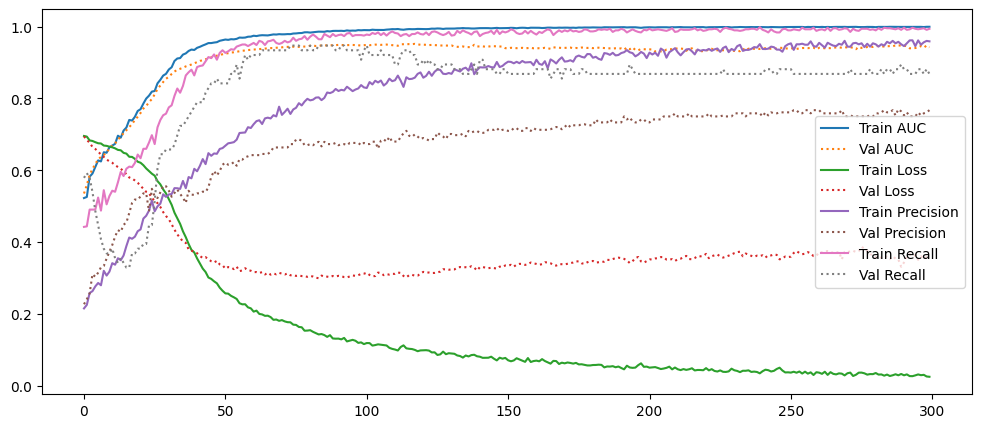

In [42]:
import matplotlib.pyplot as plt

df = pd.read_csv('training_log.csv')

plt.figure(figsize=(12, 5))
plt.plot(df['epoch'], df['auc'], label='Train AUC')
plt.plot(df['epoch'], df['val_auc'], label='Val AUC', linestyle=':')
plt.plot(df['epoch'], df['loss'], label='Train Loss')
plt.plot(df['epoch'], df['val_loss'], label='Val Loss', linestyle=':')
plt.plot(df['epoch'], df['precision'], label='Train Precision')
plt.plot(df['epoch'], df['val_precision'], label='Val Precision', linestyle=':')
plt.plot(df['epoch'], df['recall'], label='Train Recall')
plt.plot(df['epoch'], df['val_recall'], label='Val Recall', linestyle=':')
plt.legend()

plt.show()

# Evaluating the Model

In [43]:
probs = model.predict(X_test).ravel()
roc = roc_auc_score(y_test, probs)

precision, recall, thresholds = precision_recall_curve(y_test, probs)
f1s = 2 * precision * recall / (precision + recall + 1e-9)
best_thresh = thresholds[f1s.argmax()]

print("Best threshold:", best_thresh)
print("F1 @ tuned threshold:", f1_score(y_test, probs > best_thresh))

print(classification_report(y_test, probs > best_thresh))

39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
Best threshold: 0.83871573
F1 @ tuned threshold: 0.9432485322896281
              precision    recall  f1-score   support

         0.0       0.99      0.98      0.99       983
         1.0       0.93      0.96      0.94       251

    accuracy                           0.98      1234
   macro avg       0.96      0.97      0.96      1234
weighted avg       0.98      0.98      0.98      1234



In [44]:
f1  = f1_score(y_test, probs > 0.5)
print("ROC AUC:", roc)
print("F1 at 0.5:", f1)
print(classification_report(y_test, probs > 0.5))

ROC AUC: 0.993219391001609
F1 at 0.5: 0.9333333333333333
              precision    recall  f1-score   support

         0.0       0.99      0.97      0.98       983
         1.0       0.89      0.98      0.93       251

    accuracy                           0.97      1234
   macro avg       0.94      0.97      0.96      1234
weighted avg       0.97      0.97      0.97      1234



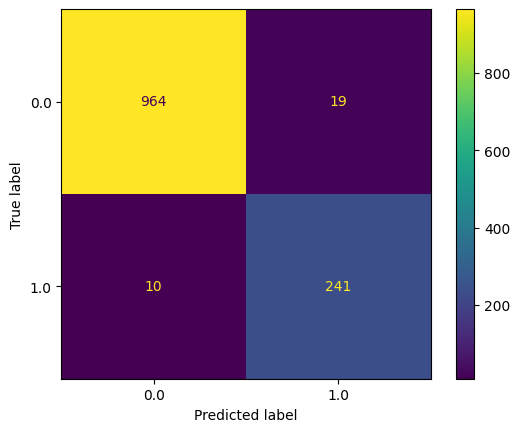

In [45]:
ConfusionMatrixDisplay.from_predictions(y_test, probs > best_thresh)

In [46]:
model_filename = 'lstm_dropout_90.keras'

model.save(model_filename) 

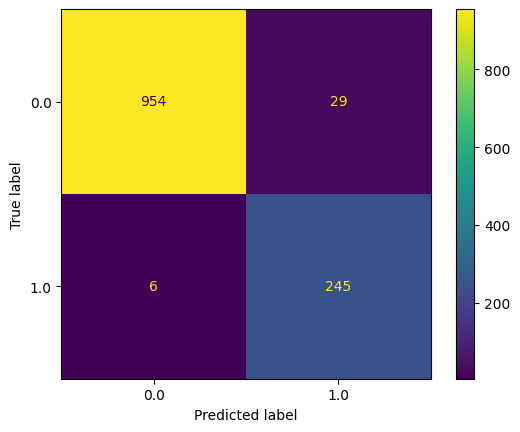

In [47]:
# Compare the performance to the default threshold (0.5)
ConfusionMatrixDisplay.from_predictions(y_test, probs > 0.5)